# 01. EDA — 유해남조류(녹조) 7일 예측 (대회 배포 번들)

**목적**: 결합 데이터(`data/processed/bloom.parquet`)의 구조·결측·계절성·지점 특성을 파악하고,
단순 베이스라인의 공식 지표를 산출해 모델이 넘어야 할 기준선을 정한다.

**번들 README 요약** (생성일 '26. 9. 12.)
- 지점 5곳: HP 해평, GJGR 강정·고령, CS 칠서, MGMR 물금·매리('20년 편입), DCHN 회남(대청호)
- 정답: 기준일+7일에 가장 가까운 측정(±3일). 채점 대상 조합은 `eval_pairs.csv`에 나열 (train 2,310 / valid 256 / test 124, excluded 64)
- 평가(test)는 '26년 **5~10월** 기준일. 지표: log10(세포수+1) RMSE·MAE, R²·NSE. 참고지표 F1@10,000
- 제출: `sample_submission.csv` 행 그대로, `pred_cells` 정수

**주의**: 번들 측정자료에 '26년 9월까지 값이 있어 test 정답도 파일에 존재한다. 결합 단계에서 test 행의 정답은 비워 두었고,
모델 입력은 기준일 이전 자료만 쓴다(규정: 기준일 이후 관측값 사용 금지, 룩업 금지).

```bash
python scripts/make_dataset.py   # data/raw 의 번들 → processed/bloom.parquet
```


In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from data_ai import viz
from data_ai.bloom import ALERT_THRESHOLDS
from data_ai.config import FIGURES_DIR, PROCESSED_DIR
from data_ai.evaluate import bloom_metrics

warnings.filterwarnings("ignore")
viz.apply_style()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 60, "display.width", 160, "display.float_format", "{:,.3f}".format)

df = pd.read_parquet(PROCESSED_DIR / "bloom.parquet")
df["date"] = pd.to_datetime(df["date"])
ORDER = ["HP", "GJGR", "CS", "MGMR", "DCHN"]                      # 고정 순서 → 색상 고정
NAME = df.groupby("station_id")["station_name"].first().to_dict()
SITES = [(s, NAME[s]) for s in ORDER if s in NAME]
SITE_COLOR = {s: viz.SERIES[i] for i, (s, _) in enumerate(SITES)}
print(df.shape, "|", df["date"].min().date(), "~", df["date"].max().date())

(2939, 126) | 2012-04-02 ~ 2026-09-10


## 1. 데이터 개요

In [2]:
overview = (
    df.groupby("station_id")
    .agg(name=("station_name", "first"), n=("date", "size"), start=("date", "min"), end=("date", "max"),
         median_gap_days=("days_since_prev", "median"), cells_missing=("cyano_cells", lambda x: x.isna().mean()),
         cells_median=("cyano_cells", "median"), cells_max=("cyano_cells", "max"))
    .reindex(ORDER)
)
display(overview)
display(pd.crosstab(df["station_name"], df["split"], margins=True))

,name,n,start,end,median_gap_days,cells_missing,cells_median,cells_max
station_id,,,,,,,,
HP,해평,566,2016-01-04,2026-09-07,7.000,0.092,97.000,"87,800.000"
GJGR,강정·고령,600,2016-01-04,2026-09-07,7.000,0.083,385.000,"489,500.000"
CS,칠서,624,2016-01-04,2026-09-10,7.000,0.045,630.500,"183,037.000"
MGMR,물금·매리,366,2020-05-11,2026-09-10,7.000,0.060,973.500,"447,075.000"
DCHN,회남,783,2012-04-02,2026-09-10,7.000,0.010,138.000,"206,126.000"


split,excluded,none,test,train,valid,All
station_name,,,,,,
강정·고령,7,53,27,458,55,600
물금·매리,14,27,27,250,48,366
칠서,13,32,25,503,51,624
해평,13,57,20,431,45,566
회남,17,16,25,668,57,783
All,64,185,124,2310,256,2939


## 2. 결측 현황
README: 수질 항목 결측 13.7%, 세포수 5.4%, 냄새물질·독소 85%+. 유량 증가 시 미채수 등. **결측 대체 전략은 평가 항목**이므로 어디에 얼마나 비어 있는지 먼저 본다.

,결측 %
mc_lr,90.700
w_solar_mean7d,16.200
chl_a,13.800
water_temp,13.700
turbidity,13.700
do,13.700
transparency,13.700
ph,13.700
target_cells,10.500
cyano_cells_lag1,5.600


수온 결측 연도별:


year,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
결측비율,1.000,1.000,1.000,1.000,0.240,0.000,0.110,0.050,0.050,0.060,0.060,0.060,0.010,0.090,0.110


findfont: Failed to find font weight normal for WenQuanYi Zen Hei, now using 500.


findfont: Failed to find font weight semibold for WenQuanYi Zen Hei, now using 500.


findfont: Failed to find font weight normal for WenQuanYi Zen Hei, now using 500.


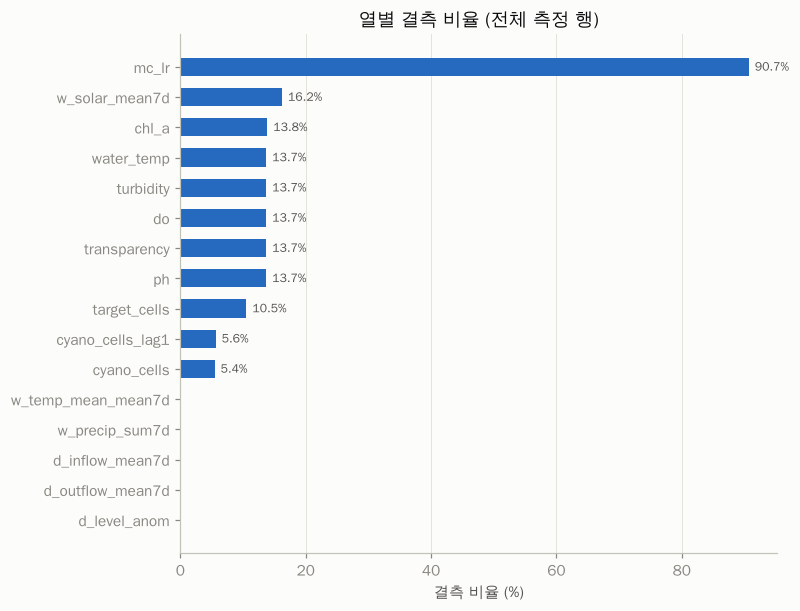

In [3]:
key_cols = ["cyano_cells", "water_temp", "ph", "do", "transparency", "turbidity", "chl_a", "mc_lr",
            "cyano_cells_lag1", "w_temp_mean_mean7d", "w_precip_sum7d", "w_solar_mean7d",
            "d_inflow_mean7d", "d_outflow_mean7d", "d_level_anom", "target_cells"]
missing = (df[key_cols].isna().mean() * 100).sort_values(ascending=False)
display(missing.round(1).to_frame("결측 %"))
print("수온 결측 연도별:")
display(df.groupby("year")["water_temp"].apply(lambda x: x.isna().mean()).round(2).to_frame("결측비율").T)

fig, ax = plt.subplots(figsize=(7, 0.32 * len(missing) + 1))
ax.barh(missing.index[::-1], missing.values[::-1], color=viz.SEQUENTIAL[4], height=0.6)
for y, v in enumerate(missing.values[::-1]):
    if v > 0:
        ax.annotate(f"{v:.1f}%", (v, y), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color=viz.INK_SECONDARY)
ax.set_xlabel("결측 비율 (%)"); ax.set_title("열별 결측 비율 (전체 측정 행)"); ax.grid(axis="y", visible=False)
fig.savefig(FIGURES_DIR / "eda_missing.png"); plt.show()

## 3. 측정 간격과 정답 간격
평상시 주 1회, 경계 이상 발령 시 주 2회 이상(README). 정답 간격(`lag_days`)은 주최 측이 4~10일로 매칭한 값이다.

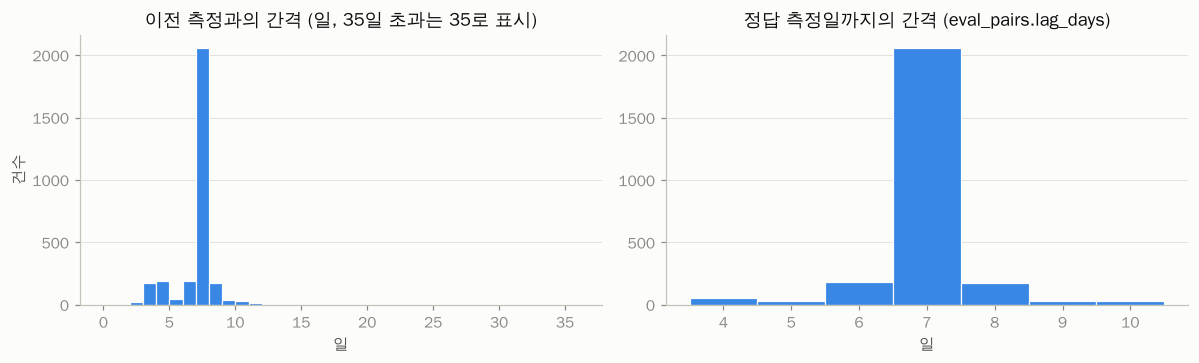

정확히 7일: 80.4% | 주 2회 측정(간격≤4일) 비율: 13.1%


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
gap = df["days_since_prev"].dropna().clip(upper=35)
axes[0].hist(gap, bins=np.arange(0, 37, 1), color=viz.SEQUENTIAL[3], edgecolor=viz.SURFACE, linewidth=0.8)
axes[0].set_title("이전 측정과의 간격 (일, 35일 초과는 35로 표시)"); axes[0].set_xlabel("일"); axes[0].set_ylabel("건수")
tg = df.loc[df["target_valid"], "target_gap_days"]
axes[1].hist(tg, bins=np.arange(3.5, 11.5, 1), color=viz.SEQUENTIAL[3], edgecolor=viz.SURFACE, linewidth=0.8)
axes[1].set_title("정답 측정일까지의 간격 (eval_pairs.lag_days)"); axes[1].set_xlabel("일")
for ax in axes: ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "eda_gaps.png"); plt.show()
print("정확히 7일:", f"{(tg == 7).mean():.1%}", "| 주 2회 측정(간격≤4일) 비율:", f"{(df['days_since_prev'] <= 4).mean():.1%}")

## 4. 지점별 세포수 시계열
로그 축. 점선은 경보 기준(관심 1,000 / 경계 10,000 / 대발생 1,000,000). 음영은 검증('25)·평가('26) 구간.

findfont: Failed to find font weight normal for WenQuanYi Zen Hei, now using 500.


findfont: Failed to find font weight semibold for WenQuanYi Zen Hei, now using 500.


findfont: Failed to find font weight normal for WenQuanYi Zen Hei, now using 500.


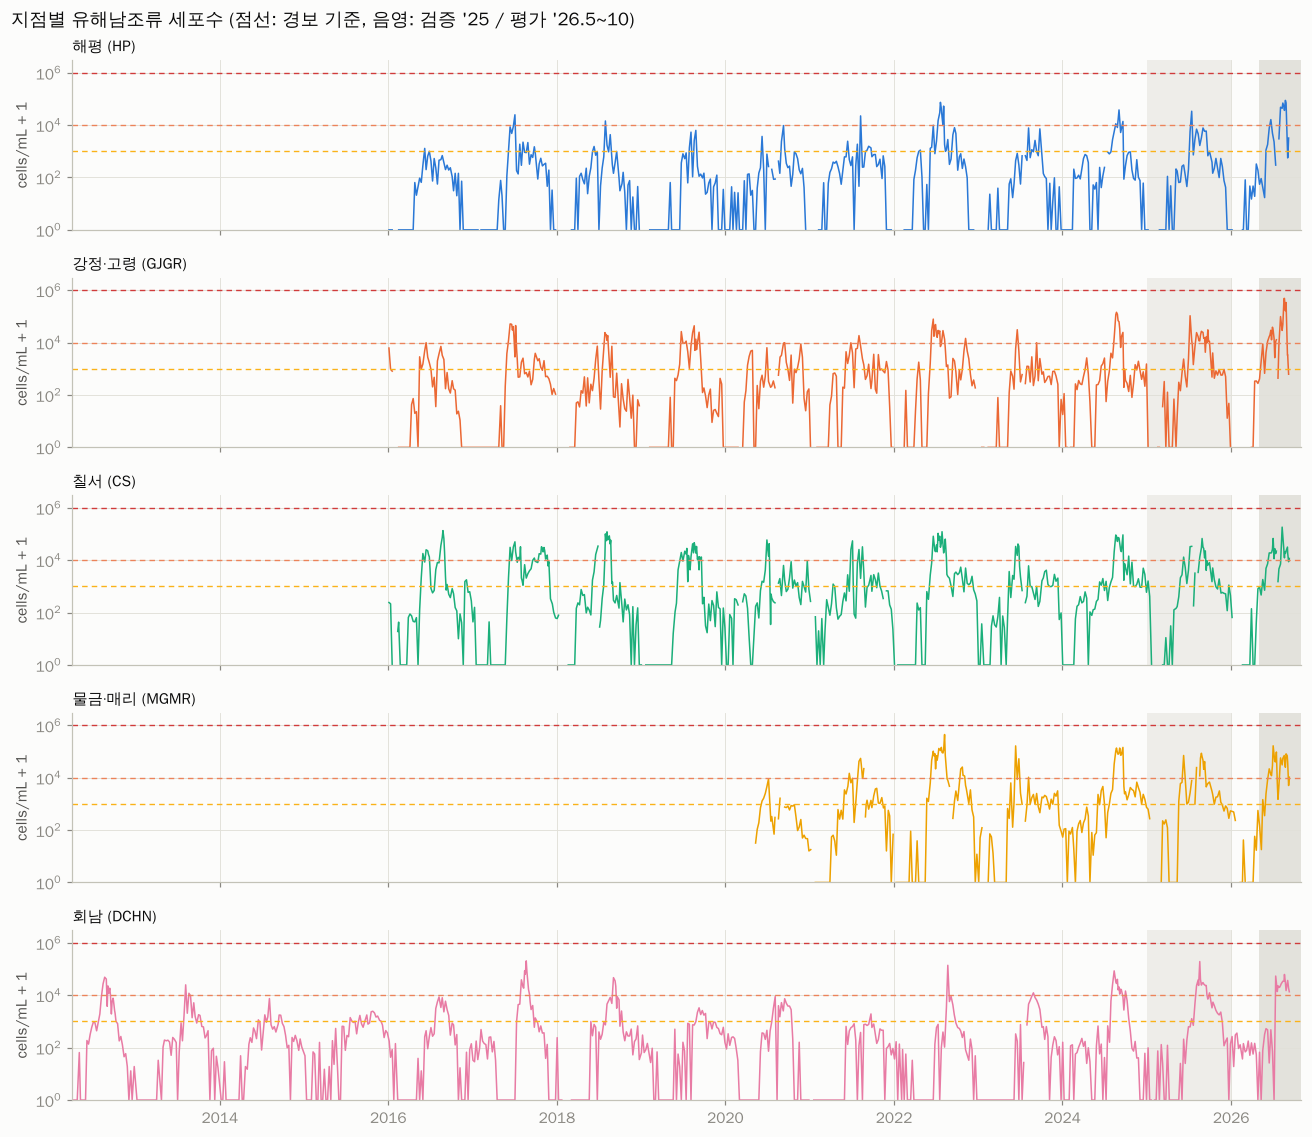

In [5]:
fig, axes = plt.subplots(len(SITES), 1, figsize=(12, 2.1 * len(SITES)), sharex=True)
for ax, (sid, name) in zip(axes, SITES):
    g = df[df["station_id"] == sid]
    ax.plot(g["date"], g["cyano_cells"] + 1, color=SITE_COLOR[sid], linewidth=1.0)
    ax.set_yscale("log"); ax.set_ylim(1, 3e6)
    for lv, (nm, v) in enumerate(ALERT_THRESHOLDS.items(), start=1):
        ax.axhline(v, color=viz.ALERT_COLORS[lv], linestyle=(0, (4, 3)), linewidth=0.9)
    ax.axvspan(pd.Timestamp("2025-01-01"), pd.Timestamp("2025-12-31"), color=viz.GRID, alpha=0.5, lw=0)
    ax.axvspan(pd.Timestamp("2026-05-01"), pd.Timestamp("2026-10-31"), color=viz.GRID, alpha=0.9, lw=0)
    ax.set_title(f"{name} ({sid})", loc="left", fontsize=10); ax.set_ylabel("cells/mL + 1")
axes[-1].set_xlim(df["date"].min(), pd.Timestamp("2026-11-01"))
fig.suptitle("지점별 유해남조류 세포수 (점선: 경보 기준, 음영: 검증 '25 / 평가 '26.5~10)", x=0.01, ha="left")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "eda_timeseries.png"); plt.show()

## 5. 계절성과 조기화
월별 log10 세포수 중앙값과, 연도별 첫 '관심'(1,000) 초과일. 과제 배경에 '첫 경보 약 2개월 조기화'가 언급되어 있다.

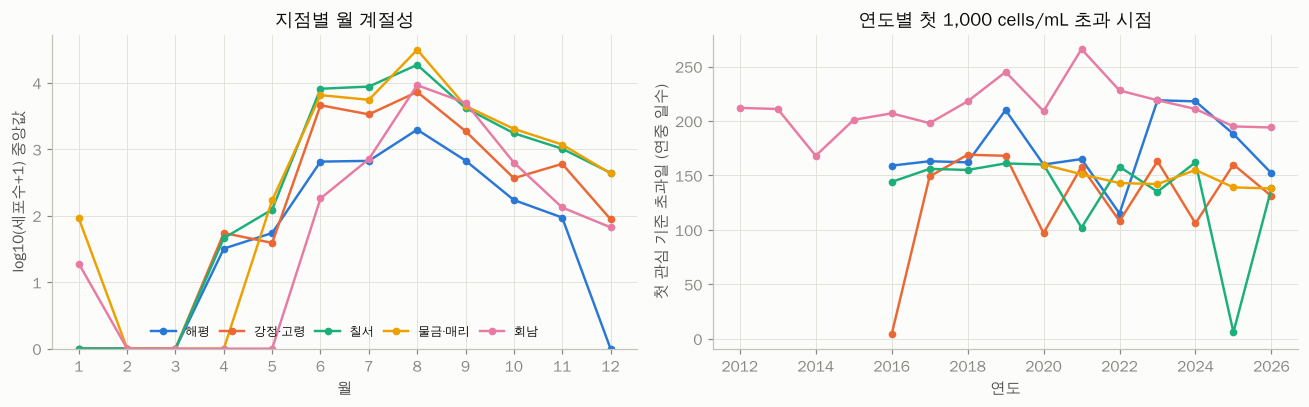

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
m = df.groupby(["station_id", "month"])["log10_cells"].median().unstack(0).reindex(columns=ORDER)
for sid, name in SITES:
    axes[0].plot(m.index, m[sid], marker="o", markersize=4, color=SITE_COLOR[sid], label=name)
axes[0].set_xticks(range(1, 13)); axes[0].set_xlabel("월"); axes[0].set_ylabel("log10(세포수+1) 중앙값")
axes[0].set_ylim(bottom=max(0, m.min().min() - 1.0)); axes[0].set_title("지점별 월 계절성")
axes[0].legend(ncol=5, fontsize=8, loc="lower center", columnspacing=0.8)
first = (df[df["cyano_cells"] >= ALERT_THRESHOLDS["관심"]].groupby(["station_id", "year"])["date"].min()
         .dt.dayofyear.unstack(0).reindex(columns=ORDER))
for sid, name in SITES:
    axes[1].plot(first.index, first[sid], marker="o", markersize=4, color=SITE_COLOR[sid], label=name)
axes[1].set_xlabel("연도"); axes[1].set_ylabel("첫 관심 기준 초과일 (연중 일수)"); axes[1].set_title("연도별 첫 1,000 cells/mL 초과 시점")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "eda_season.png"); plt.show()

## 6. 경보 단계 비율과 분할 간 분포 차이
기준일 세포수 기준. **'26년 평가 구간은 5~10월만 포함되고 심한 녹조 해**라 경계 초과 비율이 학습 구간과 크게 다르다. 모델 검증 설계 시 반드시 고려한다.

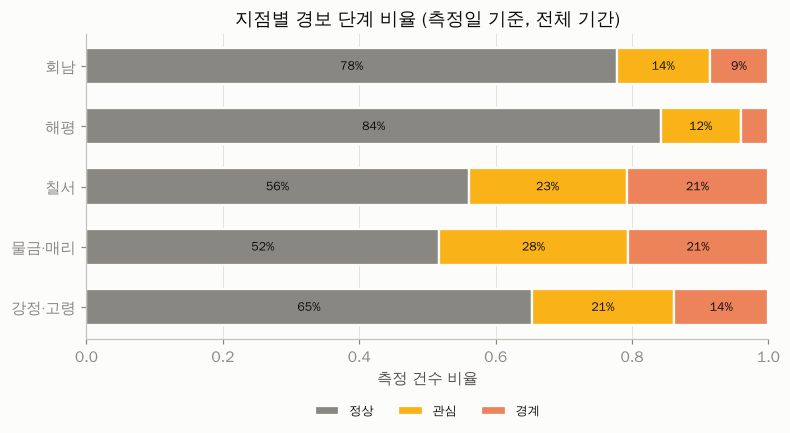

,n,over_10000,may_oct,log10_median
split,,,,
train,2310,0.099,0.553,2.355
valid,256,0.191,0.590,2.844
test,124,0.581,1.000,4.231


학습 구간 중 5~10월 기준일만 보면 경계 초과 비율: 17.2%


In [7]:
lvl = (df.dropna(subset=["current_level"]).assign(level=lambda d: d["current_level"].astype(int))
         .groupby(["station_name", "level"]).size().unstack(fill_value=0))
share = lvl.div(lvl.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(8, 3.6))
left = np.zeros(len(share))
for lv in share.columns:
    vals = share[lv].values
    ax.barh(share.index, vals, left=left, color=viz.ALERT_COLORS[lv], label=viz.ALERT_NAMES[lv], height=0.6,
            edgecolor=viz.SURFACE, linewidth=1.5)
    for y, (l0, v) in enumerate(zip(left, vals)):
        if v >= 0.06:
            ax.text(l0 + v / 2, y, f"{v:.0%}", ha="center", va="center", fontsize=8, color=viz.INK)
    left += vals
ax.set_xlim(0, 1); ax.set_xlabel("측정 건수 비율"); ax.set_title("지점별 경보 단계 비율 (측정일 기준, 전체 기간)")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18), fontsize=8); ax.grid(axis="y", visible=False)
fig.savefig(FIGURES_DIR / "eda_alert_share.png"); plt.show()

shift = (df[df["split"].isin(["train", "valid", "test"])]
         .assign(over=lambda d: d["cyano_cells"] >= 10_000, summer=lambda d: d["month"].between(5, 10))
         .groupby("split").agg(n=("date", "size"), over_10000=("over", "mean"), may_oct=("summer", "mean"),
                               log10_median=("log10_cells", "median")).reindex(["train", "valid", "test"]))
display(shift.round(3))
print("학습 구간 중 5~10월 기준일만 보면 경계 초과 비율:",
      f"{(df[(df.split=='train') & df.month.between(5,10)]['cyano_cells'] >= 10_000).mean():.1%}")

## 7. 어떤 변수가 7일 뒤 세포수와 관련 있나
선행연구(송찬영 외, 2023)는 세포수(로그)와 수온 0.63, 월 0.37, 댐 유입량 0.19, 총방류량 0.19의 상관을 보고했다. **학습 구간(~2024)** 에서 Pearson 상관을 확인한다.

,Pearson r (vs log10 정답)
log10_cells,0.821
water_temp_lag1,0.719
water_temp_lag2,0.712
water_temp,0.709
w_temp_mean_mean28d,0.695
w_ground_temp_mean28d,0.688
w_temp_max_mean28d,0.687
w_temp_min_min28d,0.683
w_temp_min_min14d,0.668
w_temp_mean_mean14d,0.667


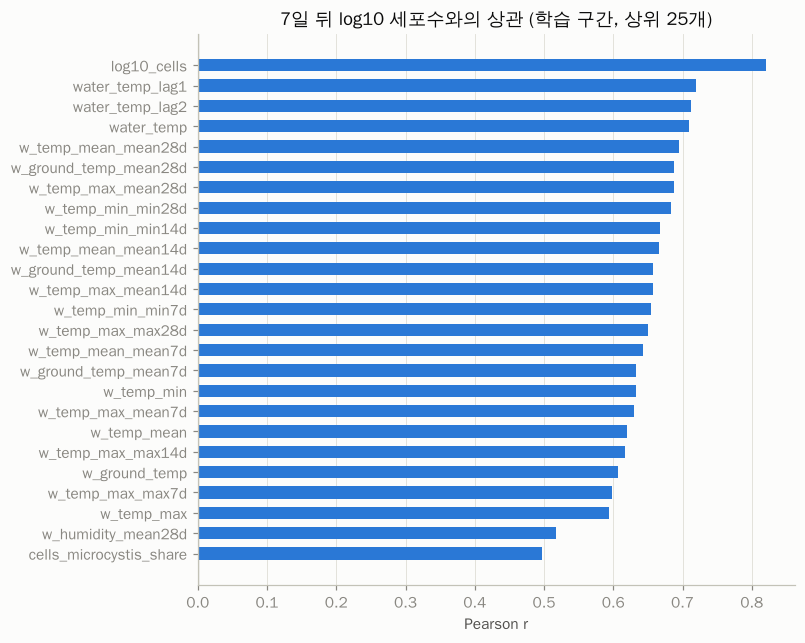

In [8]:
train = df[(df["split"] == "train") & df["target_valid"]]
cands = [c for c in df.columns if c.startswith(("w_", "d_")) or c.endswith(("_lag1", "_lag2", "_share")) or c in
         ["log10_cells", "water_temp", "ph", "do", "transparency", "turbidity", "chl_a", "month", "doy", "days_since_prev"]]
corr = train[cands + ["log10_target_cells"]].corr(numeric_only=True)["log10_target_cells"].drop("log10_target_cells")
top = corr.reindex(corr.abs().sort_values(ascending=False).index).head(25)
display(top.round(3).to_frame("Pearson r (vs log10 정답)"))

fig, ax = plt.subplots(figsize=(7, 6.5))
colors = ["#2a78d6" if v >= 0 else "#e34948" for v in top.values[::-1]]   # 양(+) 파랑 / 음(−) 빨강
ax.barh(top.index[::-1], top.values[::-1], color=colors, height=0.6)
ax.axvline(0, color=viz.MUTED, linewidth=0.8); ax.set_xlabel("Pearson r"); ax.set_title("7일 뒤 log10 세포수와의 상관 (학습 구간, 상위 25개)")
ax.grid(axis="y", visible=False); fig.savefig(FIGURES_DIR / "eda_corr.png"); plt.show()

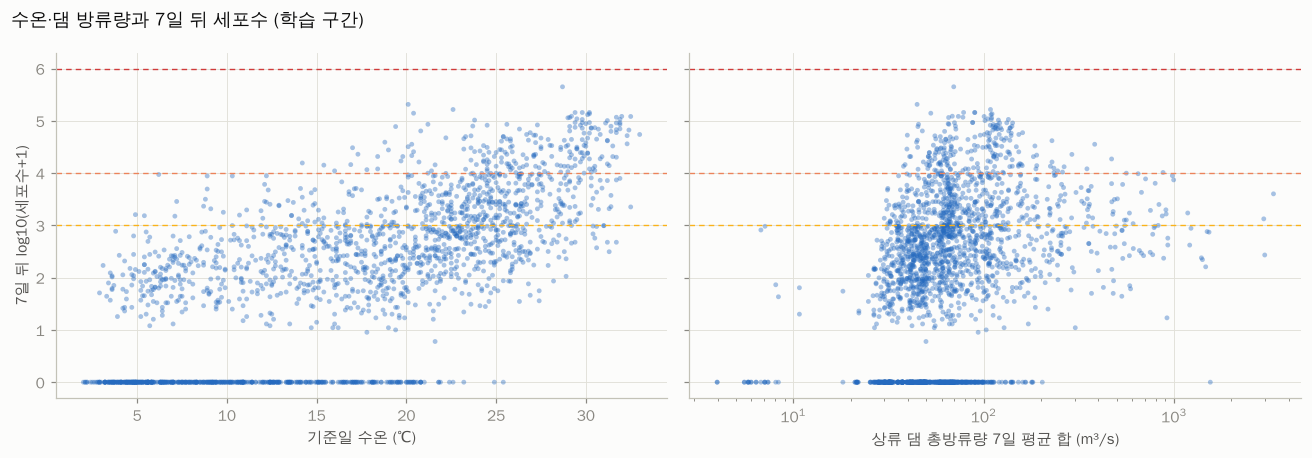

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, (x, lab) in zip(axes, [("water_temp", "기준일 수온 (℃)"), ("d_outflow_mean7d", "상류 댐 총방류량 7일 평균 합 (m³/s)")]):
    g = train.dropna(subset=[x])
    ax.scatter(g[x], g["log10_target_cells"], s=10, alpha=0.4, color=viz.SEQUENTIAL[4], edgecolor="none")
    ax.set_xlabel(lab)
    for lv, (nm, v) in enumerate(ALERT_THRESHOLDS.items(), start=1):
        ax.axhline(np.log10(v + 1), color=viz.ALERT_COLORS[lv], linestyle=(0, (4, 3)), linewidth=0.9)
axes[1].set_xscale("log")
axes[0].set_ylabel("7일 뒤 log10(세포수+1)"); fig.suptitle("수온·댐 방류량과 7일 뒤 세포수 (학습 구간)", x=0.01, ha="left")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "eda_scatter.png"); plt.show()

## 8. 베이스라인 — 모델이 넘어야 할 선
- **Persistence**: 7일 뒤 = 기준일 세포수 (기준일 값이 결측이면 직전 측정값)
- **Climatology**: 7일 뒤 = 학습 구간의 (지점, 월) 중앙값
- **Blend**: 로그 공간에서 두 값의 평균

검증('25) 구간, 공식 지표. 목표는 R² 0.6, NSE 0.5.

In [10]:
valid = df[(df["split"] == "valid") & df["target_valid"]].copy()
clim = train.groupby(["station_id", "month"])["log10_target_cells"].median().rename("clim_log10")
valid = valid.join(clim, on=["station_id", "month"])
valid["pred_persist"] = valid["cyano_cells"].fillna(valid["cyano_cells_lag1"])
valid["pred_clim"] = 10 ** valid["clim_log10"] - 1
valid["pred_blend"] = 10 ** ((np.log10(valid["pred_persist"] + 1) + valid["clim_log10"]) / 2) - 1

rows = {name: bloom_metrics(valid["target_cells"], valid[col]) for name, col in
        [("persistence", "pred_persist"), ("climatology", "pred_clim"), ("blend", "pred_blend")]}
baseline = pd.DataFrame(rows).T
display(baseline.round(3))
baseline.to_csv(FIGURES_DIR.parent / "baseline_valid_2025.csv")
print("지점별 persistence R²:")
display(valid.groupby("station_name").apply(lambda g: pd.Series(bloom_metrics(g["target_cells"], g["pred_persist"]))).round(3))

,n,rmse_log10,mae_log10,r2,nse,f1_over_threshold
persistence,253.000,0.883,0.583,-0.282,-0.282,0.727
climatology,256.000,0.907,0.680,0.028,0.028,0.189
blend,253.000,0.740,0.556,0.168,0.168,0.493


지점별 persistence R²:


,n,rmse_log10,mae_log10,r2,nse,f1_over_threshold
station_name,,,,,,
강정·고령,55.000,0.924,0.668,-0.569,-0.569,0.774
물금·매리,47.000,0.792,0.473,-0.094,-0.094,0.737
칠서,50.000,0.849,0.580,-0.281,-0.281,0.600
해평,44.000,0.856,0.565,-0.621,-0.621,0.000
회남,57.000,0.960,0.609,-0.320,-0.320,0.815


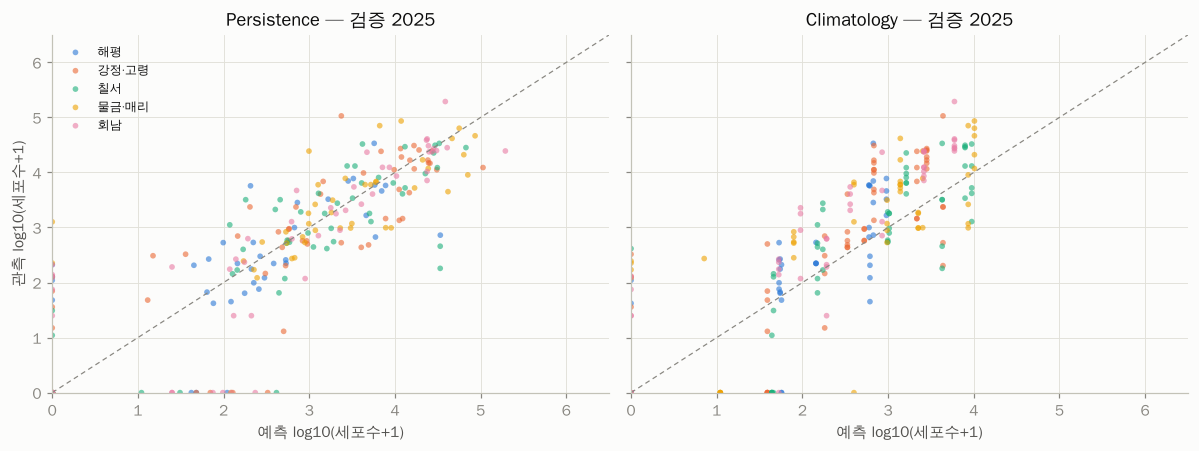

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)
for ax, (name, col) in zip(axes, [("Persistence", "pred_persist"), ("Climatology", "pred_clim")]):
    for sid, sname in SITES:
        g = valid[valid["station_id"] == sid]
        ax.scatter(np.log10(g[col] + 1), g["log10_target_cells"], s=14, alpha=0.6, color=SITE_COLOR[sid], label=sname, edgecolor="none")
    lim = (0, 6.5)
    ax.plot(lim, lim, color=viz.MUTED, linewidth=0.8, linestyle=(0, (4, 3)))
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_title(f"{name} — 검증 2025"); ax.set_xlabel("예측 log10(세포수+1)")
axes[0].set_ylabel("관측 log10(세포수+1)"); axes[0].legend(fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "eda_baseline_scatter.png"); plt.show()

## 9. 급증 사례
과제 배경: 강정·고령 '26. 8. 13. 49,400 → 8. 18. 483,021 cells/mL. 이런 급증을 7일 전에 맞히는 것이 가장 어렵고 가장 중요하다.

In [12]:
surge = df.dropna(subset=["cyano_cells", "cyano_cells_lag1"]).copy()
surge["ratio"] = (surge["cyano_cells"] + 1) / (surge["cyano_cells_lag1"] + 1)
cols = ["station_name", "date", "days_since_prev", "cyano_cells_lag1", "cyano_cells", "ratio", "water_temp",
        "w_temp_mean_mean7d", "w_precip_sum7d", "d_outflow_mean7d", "split"]
display(surge[surge["cyano_cells"] >= 10_000].sort_values("ratio", ascending=False)[cols].head(12))

,station_name,date,days_since_prev,cyano_cells_lag1,cyano_cells,ratio,water_temp,w_temp_mean_mean7d,w_precip_sum7d,d_outflow_mean7d,split
1390,회남,2026-07-13,7.000,0.000,"54,178.000","54,179.000",20.400,27.700,247.300,57.170,test
2299,해평,2021-08-09,7.000,45.000,"22,421.000",487.435,28.500,27.943,19.600,74.785,train
2749,물금·매리,2023-06-12,7.000,"1,154.000","164,455.000",142.386,26.200,21.543,4.200,96.470,train
1925,강정·고령,2025-07-07,7.000,"2,364.000","106,505.000",45.034,31.700,30.886,0.000,62.625,valid
1175,회남,2022-08-22,6.000,"3,412.000","139,682.000",40.927,21.000,26.386,124.700,72.350,train
321,칠서,2021-06-28,7.000,649.000,"25,454.000",39.162,26.700,23.429,4.600,152.823,train
615,칠서,2026-08-10,7.000,"7,113.000","183,037.000",25.729,30.700,30.186,0.000,85.067,test
2866,물금·매리,2025-08-04,7.000,990.000,"24,439.000",24.662,30.100,29.257,20.700,220.389,none
2141,해평,2018-07-30,7.000,610.000,"14,350.000",23.488,29.700,31.000,0.000,50.824,train
432,칠서,2023-06-12,7.000,"1,871.000","33,499.000",17.895,26.100,23.586,0.900,92.543,train


## 10. 정리와 다음 단계

**데이터에서 확인한 것** (위 셀 출력 기준으로 보고서에 옮길 것)
- 지점별 수록 기간·측정 수, 열별 결측 비율, 정답 간격 분포
- '26년 평가 구간의 분포 차이(5~10월 한정, 경계 초과 비율) → 검증은 **5~10월 기준일만 따로** 집계해 비교
- 베이스라인 지표 → 모델이 최소한 이 값을 넘어야 함

**다음 단계**
1. 결측 전략 3안 비교(직전값+플래그 / 지점·월 중앙값 / 모델 자체 처리)
2. LightGBM(log10 목표) + 공식 분할 + 롤링 검증('22·'23·'25) + 5~10월 부분집합 지표
3. 예측 파일 생성(`sample_submission.csv` 행 순서 유지, `pred_cells` 정수) 및 자체 채점 스크립트
